# Shared Memory

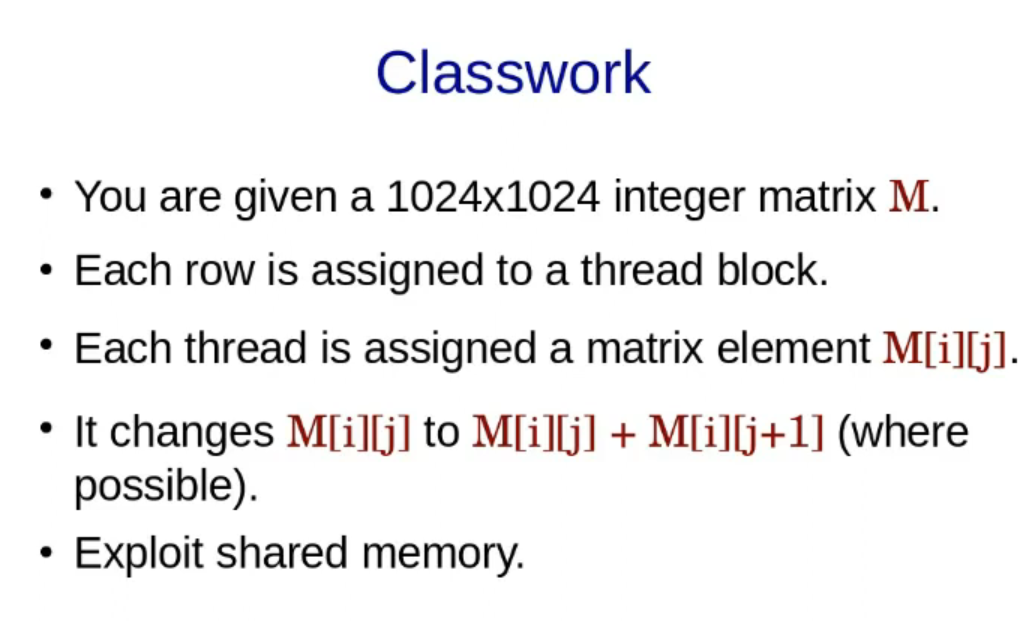

In [ ]:
!pip install git+https://github.com/andreinechaev/nvcc4jupyter.git

%load_ext nvcc4jupyter


  Cloning https://github.com/andreinechaev/nvcc4jupyter.git to /tmp/pip-req-build-i4b1_6yk
  Running command git clone --filter=blob:none --quiet https://github.com/andreinechaev/nvcc4jupyter.git /tmp/pip-req-build-i4b1_6yk
  Resolved https://github.com/andreinechaev/nvcc4jupyter.git to commit 28f872a2f99a1b201bcd0db14fdbc5a496b9bfd7
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for nvcc4jupyter: filename=nvcc4jupyter-1.2.1-py3-none-any.whl size=10741 sha256=90a829d54142cdbaf5703d6409de30ec0002408286cfbcd108dfdd84cf0ee4fe
  Stored in directory: /tmp/pip-ephem-wheel-cache-578198y3/wheels/7d/b9/66/459b9938664e6a93d1a85323ec52f7e51cd7265d253410a7d8
Successfully built nvcc4jupyter
Detected platform "Colab". Running its setup...
Source files will be saved in "/tmp/tmp45vqk3kl".


In [ ]:
%%cuda
#include<stdio.h>
#include<cuda.h>
#define BLOCKSIZE 1024

__global__ void dkernel(){
    __shared__ unsigned s;
    if (threadIdx.x == 0)
      s = 0;
    if (threadIdx.x == 1)
      s += 1;
    if (threadIdx.x == 100)
      s += 2;
    if (threadIdx.x == 0)
      printf("s = %d\n",s);
}
// thread 1 and 2 are in same warp
//whereas 100 is in different warp so no gurantee of execution order
int main(){
    dkernel<<<5,BLOCKSIZE>>>();
    cudaDeviceSynchronize();
} // this s= 3 is not always guaranteed
//there would be different copies of s

s = 3
s = 3
s = 3
s = 3
s = 3



In [ ]:
%%cuda
#include<stdio.h>
#include<cuda.h>
#define BLOCKSIZE 1024

__global__ void dkernel(){
    __shared__ unsigned s;
    if (threadIdx.x == 0)
      s = 0;
    __syncthreads();//barrier across threads in a block
    if (threadIdx.x == 1)
      s += 1;
    __syncthreads();
    if (threadIdx.x == 100)
      s += 2;
    __syncthreads();
    if (threadIdx.x == 0)
      printf("s = %d\n",s);
}
// threads must wait  in syncthreads until all the threads in the block complete its execution
int main(){
    dkernel<<<5,BLOCKSIZE>>>();
    cudaDeviceSynchronize();
}

s = 3
s = 3
s = 3
s = 3
s = 3



In [ ]:
%%cuda
#include<stdio.h>
#include<cuda.h>
#define BLOCKSIZE 26

__global__ void dkernel(){
    __shared__ char str[BLOCKSIZE + 1];
    str[threadIdx.x] = 'A' + (threadIdx.x + blockIdx.x) % BLOCKSIZE;
    if (threadIdx.x == 0)
      str[BLOCKSIZE] = '\0';
    __syncthreads(); //without this the order of printing may vary in the threads
    if (threadIdx.x == 0)
      printf("%d : %s\n",blockIdx.x,str);
}

int main(){
    dkernel<<<10,BLOCKSIZE>>>();
    cudaDeviceSynchronize();
}

2 : CDEFGHIJKLMNOPQRSTUVWXYZAB
7 : HIJKLMNOPQRSTUVWXYZABCDEFG
3 : DEFGHIJKLMNOPQRSTUVWXYZABC
8 : IJKLMNOPQRSTUVWXYZABCDEFGH
4 : EFGHIJKLMNOPQRSTUVWXYZABCD
0 : ABCDEFGHIJKLMNOPQRSTUVWXYZ
9 : JKLMNOPQRSTUVWXYZABCDEFGHI
5 : FGHIJKLMNOPQRSTUVWXYZABCDE
1 : BCDEFGHIJKLMNOPQRSTUVWXYZA
6 : GHIJKLMNOPQRSTUVWXYZABCDEF



### Preferring L1 cache


In [ ]:
%%cuda
#include<stdio.h>
#include<cuda.h>
#define BLOCKSIZE 26

__global__ void dkernel(){
    __shared__ char data[BLOCKSIZE];
    data[threadIdx.x] = threadIdx.x;
}

int main(){
    cudaFuncSetCacheConfig(dkernel,cudaFuncCachePreferL1);
    //cudaFuncSetCacheConfig(dkernel,cudaFuncCachePreferShaared);
    dkernel<<<1,BLOCKSIZE>>>();
    cudaDeviceSynchronize();
}

# Dynamic Shared Memory

it is a separate memory allocated from heap in GPU memory

In [ ]:
%%cuda
#include<stdio.h>
#include<cuda.h>

__global__ void dkernel(){
    extern __shared__ int s[]; // extern is used to identify dynamic memory
    s[threadIdx.x] = threadIdx.x;
    __syncthreads();
    if (threadIdx.x % 2)
      printf("%d\n",s[threadIdx.x]); // the printf can be jumbled there is no guarantee sequential numbering
}

int main(){
    int n;
    scanf("%d",&n);
    dkernel<<<1,n,n*sizeof(int)>>>();//dynamic shared memory is specified by third parameter interms of bytes
    cudaDeviceSynchronize();
    return 0;
}

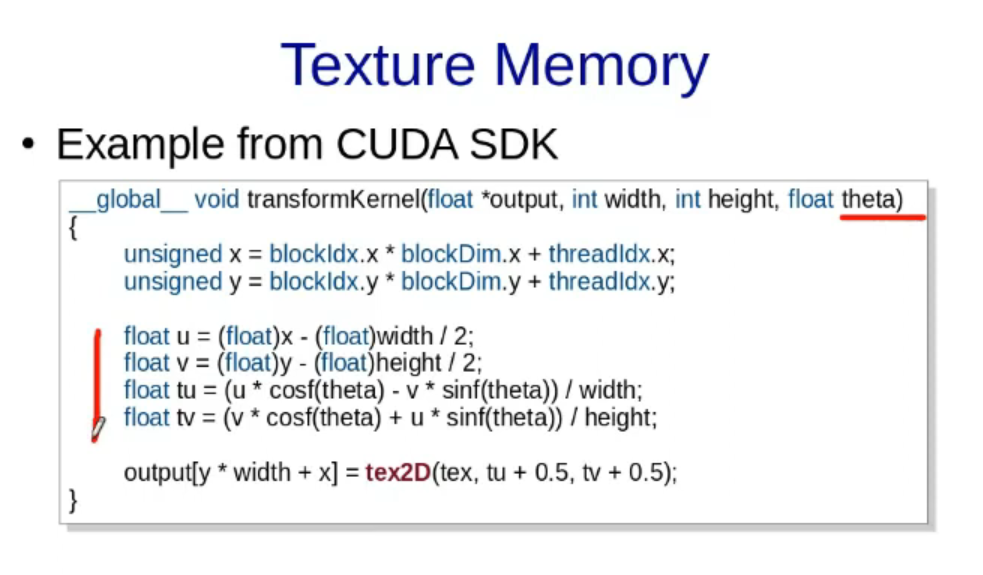

# Constant memory

In [ ]:
%%cuda
#include<stdio.h>
#include<cuda.h>

__constant__ unsigned meta[1];

__global__ void dkernel(unsigned *data){
    data[threadIdx.x] = meta[0];
}

__gloabal__ void print(unsigned *data){
    printf("%d %d\n",threadIdx.x,data[threadIdx.x]);
}

int main(){
    unsigned hmeta = 10;
    cudaMemcpyToSymbol(meta.&hmeta,sizeof(unsigned));
    unsigned *data;
    cudaMalloc(&data,32*sizeof(unsigned));
    dkernel<<<1,32>>>(data);
    cudaDeviceSynchronize();
    print<<<1,32>>>(data);
    cudaDeviceSynchronize();
    return 0;
}

# Shared Memory with Multiple arrays

In [ ]:
%%cuda
#include<stdio.h>
#include<cuda.h>

__global__ void dkernel(int sz,int n1){
    extern __shared__ int s[];
    int *s1 = s;
    int *s2 = s + n1;
    if (threadIdx.x < n1)
      s1[threadIdx.x] = threadIdx.x;
    if (threadIdx.x < (sz - n1))
      s2[threadIdx.x] = threadIdx.x * 100;
    if (threadIdx.x < sz && threadIdx.x % 2)
      printf("%d\n",s1[threadIdx.x]);
}

int main(){
    int sz;
    scanf("%d",&sz);
    print<<<1,1024,sz*sizeof(int)>>>(sz,sz/2);
    cudaDeviceSynchronize();
    return 0;
}

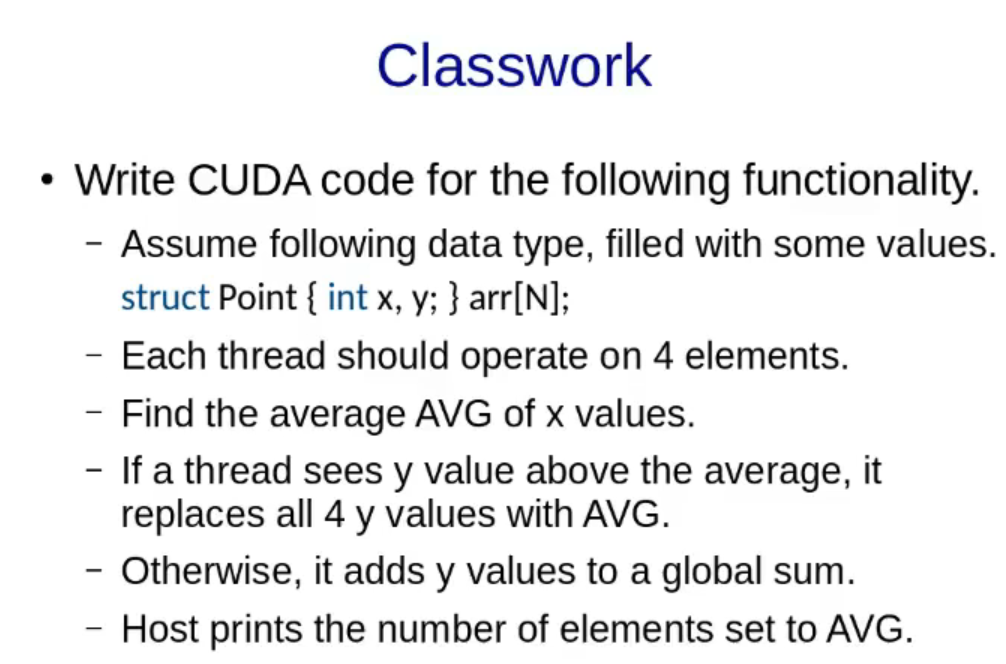

In [ ]:
%%cuda
#include<stdio.h>
#include<cuda.h>

struct Point{
    int x,y;
};

__global__ void avgx(Point *a,int *sum){
    __shared__ int s[16];

    int t = threadIdx.x;

    s[t] = a[t].x;
    __syncthreads();

    if(t==0){
        *sum = 0;
        for(int i=0;i<16;i++)
            *sum += s[i];
    }
}
__global__ void process(Point *a,int avg,int *ysum,int *cnt){
    __shared__ int sy[4];
    __shared__ int sc[4];

    int t = threadIdx.x;
    int start = t*4;

    int flag = 0;
    int local = 0;
    int c = 0;

    for(int i=0;i<4;i++){
        if(a[start+i].y > avg)
            flag = 1;
        local += a[start+i].y;
    }

    if(flag){
        for(int i=0;i<4;i++){
            a[start+i].y = avg;
            c++;
        }
        local = 0;
    }

    sy[t] = local;
    sc[t] = c;

    __syncthreads();

    if(t==0){
        *ysum = 0;
        *cnt = 0;

        for(int i=0;i<4;i++){
            *ysum += sy[i];
            *cnt += sc[i];
        }
}